# 07 · Simplificación: qué etapas del detector hacen falta

La auditoría de decisiones encontró siete etapas que se agregaron por un razonamiento razonable, pero sin mostrar con los datos que hacen falta. Este notebook aplica la **regla de sencillez**: si no se puede demostrar que la alternativa más simple es peor, se usa la más simple.

**El criterio se escribió y se subió al repositorio antes de correr este notebook** (`docs/criterio_parsimonia.md`). Acá se aplica tal cual. Las decisiones las toma el código a partir de los valores p, con la regla escrita de antemano. Una etapa se mantiene solo si cumple al menos una de estas condiciones:

| Condición | Qué quiere decir |
|---|---|
| (a) La exige la consigna | La consigna pide implementar los temas obligatorios (filtros óptimos, realizaciones, Lomb), y eso ya está hecho en `03` y `04`. No obliga a usarlos en el detector final, así que no mantiene ninguna de estas etapas |
| (b) Mejora la medición de su paso | Mejora de forma demostrable la ubicación del pico R, o el parecido de la EDR con la respiración registrada, contra una referencia de los datos |
| (c) Mejora el detector | Mejora de forma demostrable la exactitud en validación cruzada por personas |
| (d) Corrige una falla del detector | Para la exclusión de minutos y la confianza, que no cambian la decisión sino cuándo se decide o qué se informa |

**"De forma demostrable"** quiere decir que la diferencia está a favor de la etapa y que su valor p, corregido por Holm dentro de su familia, es menor que 0,05.

**Solo se usan los registros de desarrollo.** Test ya se usó una vez para evaluar la versión congelada (`05`); sus resultados siguen siendo la evaluación independiente de esa versión y no se usan acá para nada. El detector simplificado queda medido solo con validación cruzada: no tiene una evaluación independiente.

In [1]:
import json
import sys
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from src.config import MIN_MINUTES_PER_CLASS, MINUTE_MAX_CORRECTED, SPLIT_CSV
from src.data import load_ecg, load_qrs
from src.estadistica import p_bootstrap, tabla_holm
from src.evaluation.cv import GRILLA_W, auc, cv_c, exactitud, grupos_personas, metricas, sorteos_personas
from src.features.build import record_series
from src.features.detector import BAND, WINDOW_S, c_score, evaluable, fit_c, minute_table, save_params, youden_threshold
from src.features.edr import qrs_reference
from src.preprocessing.filters import apply_zero_phase, design_bandpass
from src.qrs.quantization import two_phase_peaks
from src.config import ECG_FILTER
from src.viz.plots import ANCHO, APNEA, COLORES_CAT, GRIS, NORMAL, save, setup

setup()
split = pd.read_csv(SPLIT_CSV)
DEV = split[split.set == "dev"].record.tolist()
SUJETO = split.set_index("record").subject
CATEGORIA = split.set_index("record").category
SORTEOS = sorteos_personas(SUJETO[DEV].unique(), n=4000, semilla=2026)
print(f"{len(DEV)} registros de desarrollo, {SUJETO[DEV].nunique()} personas; {len(SORTEOS)} sorteos de bootstrap")

47 registros de desarrollo, 19 personas; 4000 sorteos de bootstrap


## 1. Las etapas y su alternativa simple

Cada alternativa cambia **una sola etapa** y deja las demás como están. La alternativa simple es no hacer el paso; cuando el paso es una opción de una herramienta estándar, es su valor por defecto.

| # | Etapa | Actual | Alternativa simple |
|---|---|---|---|
| 1 | Refinamiento del pico R | Vértice de una parábola por 3 muestras | El pico en la muestra (10 ms de resolución) |
| 2 | Wiener antes de medir la EDR | FIR de 129 coeficientes | Sin Wiener |
| 3 | Excluir de la EDR los latidos ectópicos | Sí | No |
| 4 | Filtro de Hampel en la EDR | Sí | No |
| 5 | Interpolación a 2 Hz | Spline cúbico | Lineal |
| 6 | Tendencia en cada segmento de Welch | Se quita una recta | Se quita la media (valor por defecto de `scipy.signal.welch`) |
| 7 | Excluir los minutos con más de 20 % de RR corregidos | No se clasifican ni se usan para ajustar | Se clasifican todos |
| 8 | Confianza según el movimiento | Alta, media o baja | No se informa |

**Sobre la etapa 6.** Con la ventana de Hann periódica que usa Welch, la media del segmento solo aparece en las frecuencias k = 0 y 1, fuera de la banda de la feature (k = 2…6). Por eso quitar la media o no quitar nada da exactamente lo mismo en la banda. Se verifica:

In [2]:
from scipy.signal import get_window

ventana = get_window("hann", int(WINDOW_S * 2.0) // 2)
fuga = np.abs(np.fft.rfft(ventana))
print("módulo de la DFT de la ventana de Hann en k = 0…7:", np.round(fuga[:8], 9))

módulo de la DFT de la ventana de Hann en k = 0…7: [120.  60.   0.   0.   0.   0.   0.   0.]


Para las etapas 1 a 6 se recalculan las tablas por minuto de los 47 registros con la etapa cambiada. Las etapas 7 y 8 usan la tabla actual.

In [3]:
OPCION = {1: {"refine": False}, 2: {"wiener": False}, 3: {"exclude_ectopic": False}, 4: {"hampel": False},
          5: {"interp": "linear"}, 6: {"detrend": "constant"}}
ETAPAS = {1: "Refinamiento del pico R", 2: "Wiener en la EDR", 3: "Excluir ectópicos de la EDR", 4: "Hampel en la EDR",
          5: "Spline cúbico", 6: "Quitar la recta en Welch", 7: "Excluir minutos con > 20 % de RR corregidos",
          8: "Confianza según el movimiento"}
SIMPLE = {1: "pico en la muestra", 2: "sin Wiener", 3: "sin excluirlos", 4: "sin Hampel", 5: "interpolación lineal",
          6: "quitar la media", 7: "clasificar todos los minutos", 8: "no informarla"}


def tabla_variante(args):
    rec, op = args
    kw = {k: v for k, v in op.items() if k != "detrend"}
    return minute_table(rec, series=record_series(rec, **kw), detrend_type=op.get("detrend"))


def tablas_de(op):
    with ProcessPoolExecutor(4) as ex:
        t = pd.concat(list(ex.map(tabla_variante, [(r, op) for r in DEV])), ignore_index=True)
    return t.assign(subject=t.record.map(SUJETO))


TABLAS = {frozenset(): tablas_de({})}
for k_, op_ in OPCION.items():
    TABLAS[frozenset({k_})] = tablas_de(op_)
T_ACT = TABLAS[frozenset()]


def tabla_comb(quitar):
    """Tabla por minuto con las etapas `quitar` (1 a 6) reemplazadas por su alternativa simple."""
    clave = frozenset(k for k in quitar if k in OPCION)
    if clave not in TABLAS:
        op = {}
        for k in clave:
            op.update(OPCION[k])
        TABLAS[clave] = tablas_de(op)
    return TABLAS[clave]


print({f"{sorted(k) or 'actual'}": len(v) for k, v in TABLAS.items()})

{'actual': 22907, '[1]': 22907, '[2]': 22907, '[3]': 22907, '[4]': 22907, '[5]': 22907, '[6]': 22907}


## 2. Condición (b): ¿mejora la medición de su paso?

**Refinamiento del pico R.** Se usa la prueba de dos fases de `02` §3, ahora en los 47 registros de desarrollo. El ECG se baja a 50 Hz tomando las muestras pares por un lado y las impares por otro, así cada latido queda medido en dos grillas corridas 10 ms. Si el refinamiento recupera la posición entre muestras, las dos mediciones del mismo latido coinciden. La medida es el desacuerdo medio de cada registro, sin refinar menos refinado. El valor p sale de un bootstrap de personas y, como la familia tiene una sola comparación, no hace falta corregirlo. La medición no usa etiquetas.

In [4]:
sos = design_bandpass(100, *ECG_FILTER)
PERSONAS = sorted(SUJETO[DEV].unique())


def desacuerdo_dos_fases(rec):
    ecg, fs = load_ecg(rec)
    x = apply_zero_phase(ecg, sos)
    q = load_qrs(rec)
    off, sign = qrs_reference(x, q, fs)
    tf = two_phase_peaks(x, q, fs, off, sign)
    return {"record": rec, "sin refinar (ms)": 1000 * np.abs(tf.par - tf.impar).mean(),
            "refinado (ms)": 1000 * np.abs(tf.par_ref - tf.impar_ref).mean()}


with ProcessPoolExecutor(4) as ex:
    fases = pd.DataFrame(list(ex.map(desacuerdo_dos_fases, DEV)))
fases["subject"] = fases.record.map(SUJETO)
fases["mejora (ms)"] = fases["sin refinar (ms)"] - fases["refinado (ms)"]


def prueba_1b(personas, sorteos):
    """Mejora media del desacuerdo entre fases (ms) con las personas dadas, y su distribución bootstrap."""
    f = fases[fases.subject.isin(personas)]
    g = f.groupby("subject")["mejora (ms)"].agg(["sum", "size"])
    boot = np.array([g["sum"].reindex(so).sum() / g["size"].reindex(so).sum() for so in sorteos])
    return float(f["mejora (ms)"].mean()), boot


d_1b, boot_1b = prueba_1b(PERSONAS, SORTEOS)
print(f"desacuerdo medio entre fases: sin refinar {fases['sin refinar (ms)'].mean():.2f} ms, refinado {fases['refinado (ms)'].mean():.2f} ms; "
      f"mejora {d_1b:.2f} ms (IC 95 % {np.percentile(boot_1b, 2.5):.2f} a {np.percentile(boot_1b, 97.5):.2f}); "
      f"mejora en {int((fases['mejora (ms)'] > 0).sum())}/{len(fases)} registros; p = {p_bootstrap(boot_1b):.4f}")

desacuerdo medio entre fases: sin refinar 10.03 ms, refinado 2.33 ms; mejora 7.69 ms (IC 95 % 7.61 a 7.77); mejora en 47/47 registros; p = 0.0000


**Wiener, ectópicos y Hampel.** Su efecto sobre el parecido de la EDR con la respiración registrada ya se midió en `03` §6 (8 registros con respiración), con corrección de Holm sobre las 12 comparaciones. Esa medición no usa las etiquetas de apnea. Ningún paso mejora de forma demostrable:

| Etapa | Coherencia en la banda respiratoria (A1), p de Holm | Coherencia en la banda de la apnea (A2), p de Holm |
|---|---|---|
| 2 · Wiener (después de los otros dos pasos) | 1,0 | 1,0 |
| 3 · Excluir ectópicos (contra la primera versión) | 1,0 | 1,0 |
| 4 · Hampel (después de excluir ectópicos) | 1,0 | 1,0 |

Para esas tres etapas no se cumple (b): falta ver si cumplen (c).

## 3. Condiciones (c) y (d): validación cruzada por personas

Es la misma validación cruzada de `04` §15 (`src/evaluation/cv.py`). Las 19 personas se reparten en 5 grupos. Con los otros 4 se estandarizan los términos de C, se elige w y se fija el umbral de Youden; después se clasifica el grupo que quedó afuera. Así cada minuto lo clasifica un detector que no vio a su persona. Para el detector actual, la función da exactamente el resultado de `04`.

Cada comparación es **pareada**: se hace sobre los minutos que clasifican las dos versiones, con los mismos sorteos de personas. La diferencia se escribe siempre de modo que **un valor positivo favorece a la etapa**. Todo el procedimiento está en funciones que reciben las personas con las que se trabaja; en la sección 8 se repite sin las personas de cada grupo.

In [5]:
NOMBRES = {1: "1c · actual − sin refinamiento del pico R", 2: "2c · actual − sin Wiener",
           3: "3c · actual − sin excluir ectópicos de la EDR", 4: "4c · actual − sin Hampel en la EDR",
           5: "5c · actual − interpolación lineal", 6: "6c · actual − quitando solo la media",
           "7a": "7a · exactitud en minutos limpios − en los que se excluirían",
           "7b": "7b · actual − ajustado con todos los minutos",
           8: "8 · exactitud con confianza alta − con baja"}


def con_ev(t, max_corrected=MINUTE_MAX_CORRECTED):
    e = t[evaluable(t, max_corrected)]
    return e[np.isfinite(e.P_RR) & np.isfinite(e.EDR_noche)]


def de(t, personas):
    return t[t.subject.isin(personas)]


def comparar(r_a, r_b, sorteos):
    """Exactitud de a − b sobre los minutos que clasifican los dos: (diferencia, bootstrap, minutos)."""
    m = r_a.merge(r_b, on=["record", "minute"], suffixes=("_a", "_b"))
    ok_a = (m.pred_a == m.label_a).to_numpy(); ok_b = (m.pred_b == m.label_b).to_numpy()
    d = exactitud(ok_a, m.subject_a) - exactitud(ok_b, m.subject_a)
    boot = exactitud(ok_a, m.subject_a, sorteos) - exactitud(ok_b, m.subject_a, sorteos)
    return d, boot, len(m)


def diferencia_entre(ok, sujetos, sel1, sel2, sorteos):
    """Exactitud en los minutos sel1 − en los minutos sel2, con el mismo detector."""
    s = np.asarray(sujetos)
    if sel1.sum() == 0 or sel2.sum() == 0:
        return np.nan, np.full(len(sorteos), np.nan), int(sel1.sum() + sel2.sum())
    d = exactitud(ok[sel1], s[sel1]) - exactitud(ok[sel2], s[sel2])
    boot = exactitud(ok[sel1], s[sel1], sorteos) - exactitud(ok[sel2], s[sel2], sorteos)
    return d, boot, int(sel1.sum() + sel2.sum())


def pruebas_etapas(personas, sorteos):
    """Las 9 pruebas de (c) y (d) con las personas dadas."""
    r_a = cv_c(con_ev(de(T_ACT, personas)))
    cvs = {k: cv_c(con_ev(de(tabla_comb({k}), personas))) for k in OPCION}
    fam = {NOMBRES[k]: comparar(r_a, cvs[k], sorteos) for k in OPCION}
    r_t = cv_c(con_ev(de(T_ACT, personas), None))
    limpio = (r_t.q <= MINUTE_MAX_CORRECTED).to_numpy()
    fam[NOMBRES["7a"]] = diferencia_entre((r_t.pred == r_t.label).to_numpy(), r_t.subject, limpio, ~limpio, sorteos)
    fam[NOMBRES["7b"]] = comparar(r_a, r_t, sorteos)
    ok_a = (r_a.pred == r_a.label).to_numpy()
    fam[NOMBRES[8]] = diferencia_entre(ok_a, r_a.subject, (r_a.confianza == "alta").to_numpy(),
                                       (r_a.confianza == "baja").to_numpy(), sorteos)
    return fam, r_a, r_t, cvs


FAM, r_act, r_todos, CVS = pruebas_etapas(PERSONAS, SORTEOS)
print("detector actual:", {k: round(v, 3) for k, v in metricas(r_act.label, r_act.pred).items()},
      "· pesos por grupo:", r_act.groupby("grupo").w.first().tolist())
pd.DataFrame({ETAPAS[k] + f" ({SIMPLE[k]})": metricas(r.label, r.pred) for k, r in CVS.items()}).T.round(3)

detector actual: {'sensibilidad': 0.814, 'especificidad': 0.851, 'exactitud': 0.836} · pesos por grupo: [1.5, 0.75, 1.0, 1.25, 1.0]


,sensibilidad,especificidad,exactitud
Refinamiento del pico R (pico en la muestra),0.810,0.855,0.837
Wiener en la EDR (sin Wiener),0.780,0.863,0.830
Excluir ectópicos de la EDR (sin excluirlos),0.818,0.846,0.834
Hampel en la EDR (sin Hampel),0.811,0.822,0.817
Spline cúbico (interpolación lineal),0.814,0.843,0.831
Quitar la recta en Welch (quitar la media),0.805,0.861,0.838


**Etapa 7, exclusión de minutos.** Se ajusta y se clasifica con todos los minutos con etiqueta. Hay dos pruebas:
- **7a (d), ¿falla el detector en los minutos que se excluyen?** Con el detector sin exclusión, exactitud en los minutos con 20 % o menos de RR corregidos menos la exactitud en los demás (más de 20 %, o sin latidos).
- **7b (c), ¿ajustar sin esos minutos mejora el detector?** Sobre los minutos con 20 % o menos: el actual contra el ajustado con todos.

In [6]:
limpio = (r_todos.q <= MINUTE_MAX_CORRECTED).to_numpy()
ok_t = (r_todos.pred == r_todos.label).to_numpy()
print(f"minutos con etiqueta: {len(r_todos)}; con más de 20 % de RR corregidos o sin latidos: {int((~limpio).sum())} "
      f"({100 * (~limpio).mean():.2f} %), de {r_todos[~limpio].subject.nunique()} personas")
print(f"exactitud sin exclusión: minutos limpios {exactitud(ok_t[limpio], r_todos.subject[limpio]):.3f}, "
      f"minutos que se excluirían {exactitud(ok_t[~limpio], r_todos.subject[~limpio]):.3f}")

minutos con etiqueta: 22907; con más de 20 % de RR corregidos o sin latidos: 135 (0.59 %), de 9 personas
exactitud sin exclusión: minutos limpios 0.823, minutos que se excluirían 0.637


**Etapa 8, confianza.** Con el detector actual, exactitud en los minutos de confianza alta menos la exactitud en los de baja. Los cortes (percentiles 50 y 90 del movimiento) se calculan en cada grupo de entrenamiento, sin las personas que se clasifican.

In [7]:
r_act.assign(ok=r_act.pred == r_act.label).groupby("confianza").agg(
    minutos=("ok", "size"), exactitud=("ok", "mean"), apnea=("label", "mean")).loc[["alta", "media", "baja"]].round(3)

,minutos,exactitud,apnea
confianza,,,
alta,11389,0.862,0.388
media,8999,0.822,0.426
baja,2384,0.762,0.379


## 4. Corrección de Holm y decisión

La familia son las 9 pruebas de (c) y (d). Que la probabilidad de error de toda la familia no supere el 5 % quiere decir que la probabilidad de conservar alguna etapa innecesaria tampoco lo supera. Una prueba se cumple si la diferencia es positiva (a favor de la etapa) y su p de Holm es menor que 0,05. **La decisión sale de aplicar la regla**: una etapa se mantiene si cumple (b), (c) o (d).

In [8]:
def decidir(fam, personas, sorteos):
    """Aplica el criterio: qué condiciones cumple cada etapa, y la tabla de Holm."""
    holm = tabla_holm({k: v[:2] for k, v in fam.items()})

    def ok(k):
        n = NOMBRES[k]
        return bool(n in holm.index and holm.loc[n, "diferencia"] > 0 and holm.loc[n, "p de Holm"] < 0.05)

    d1, b1 = prueba_1b(personas, sorteos)
    cumple = {1: {"b": bool(d1 > 0 and p_bootstrap(b1) < 0.05), "c": ok(1)},
              2: {"b": False, "c": ok(2)}, 3: {"b": False, "c": ok(3)}, 4: {"b": False, "c": ok(4)},
              5: {"c": ok(5)}, 6: {"c": ok(6)}, 7: {"d (7a)": ok("7a"), "c (7b)": ok("7b")}, 8: {"d": ok(8)}}
    return cumple, holm


CUMPLE, holm = decidir(FAM, PERSONAS, SORTEOS)
orden = [n for n in NOMBRES.values() if n in holm.index]
holm["IC 95 %"] = [f"{np.nanpercentile(FAM[k][1], 2.5):+.4f} a {np.nanpercentile(FAM[k][1], 97.5):+.4f}" for k in holm.index]
holm["minutos comparados"] = [FAM[k][2] for k in holm.index]
holm["se cumple"] = np.where((holm["diferencia"] > 0) & (holm["p de Holm"] < 0.05), "sí", "no")
holm.loc[orden, ["diferencia", "IC 95 %", "p", "p de Holm", "se cumple", "minutos comparados"]].round(4)

,diferencia,IC 95 %,p,p de Holm,se cumple,minutos comparados
comparación,,,,,,
1c · actual − sin refinamiento del pico R,-0.0013,-0.0040 a +0.0013,0.3295,1.000,no,22769
2c · actual − sin Wiener,0.0060,-0.0240 a +0.0412,0.7530,1.000,no,22772
3c · actual − sin excluir ectópicos de la EDR,0.0015,-0.0074 a +0.0120,0.8980,1.000,no,22772
4c · actual − sin Hampel en la EDR,0.0186,+0.0079 a +0.0302,0.0000,0.000,sí,22772
5c · actual − interpolación lineal,0.0047,-0.0041 a +0.0152,0.3935,1.000,no,22772
6c · actual − quitando solo la media,-0.0024,-0.0061 a +0.0011,0.1940,1.000,no,22772
7a · exactitud en minutos limpios − en los que se excluirían,0.1864,-0.1011 a +0.3280,0.1855,1.000,no,22907
7b · actual − ajustado con todos los minutos,0.0125,+0.0016 a +0.0270,0.0210,0.147,no,22772
8 · exactitud con confianza alta − con baja,0.1001,+0.0204 a +0.1746,0.0175,0.140,no,13773


PosixPath('/home/user/TP-PSB-G8/informe/figuras/07_etapas.png')

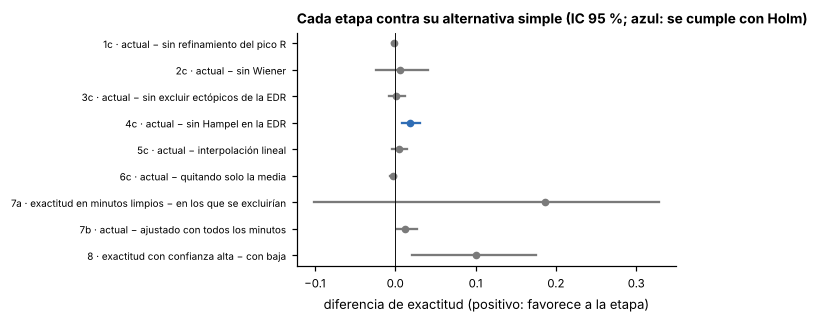

In [9]:
fig, ax = plt.subplots(figsize=(ANCHO, 3.0))
for i, k in enumerate(orden[::-1]):
    lo, hi = np.nanpercentile(FAM[k][1], [2.5, 97.5])
    color = NORMAL if holm.loc[k, "se cumple"] == "sí" else GRIS
    ax.plot([lo, hi], [i, i], color=color, lw=1.5)
    ax.plot(FAM[k][0], i, "o", color=color, ms=4)
ax.axvline(0, color="black", lw=0.6)
ax.set_yticks(range(len(orden))); ax.set_yticklabels([k[:60] for k in orden[::-1]], fontsize=6.5)
ax.set(xlabel="diferencia de exactitud (positivo: favorece a la etapa)",
       title="Cada etapa contra su alternativa simple (IC 95 %; azul: se cumple con Holm)")
fig.tight_layout()
save(fig, "07_etapas")

In [10]:
MANTENER = {k: any(v.values()) for k, v in CUMPLE.items()}
pd.DataFrame([{"etapa": f"{k} · {ETAPAS[k]}",
               "condiciones que cumple": ", ".join(c for c, ok in CUMPLE[k].items() if ok) or "ninguna",
               "decisión": "se mantiene" if MANTENER[k] else f"se reemplaza: {SIMPLE[k]}"} for k in ETAPAS]).set_index("etapa")

,condiciones que cumple,decisión
etapa,,
1 · Refinamiento del pico R,b,se mantiene
2 · Wiener en la EDR,ninguna,se reemplaza: sin Wiener
3 · Excluir ectópicos de la EDR,ninguna,se reemplaza: sin excluirlos
4 · Hampel en la EDR,c,se mantiene
5 · Spline cúbico,ninguna,se reemplaza: interpolación lineal
6 · Quitar la recta en Welch,ninguna,se reemplaza: quitar la media
7 · Excluir minutos con > 20 % de RR corregidos,ninguna,se reemplaza: clasificar todos los minutos
8 · Confianza según el movimiento,ninguna,se reemplaza: no informarla


**Qué cambia sin el filtro de Hampel.** Sin Hampel, el nivel nocturno de la EDR cambia poco en casi todas las noches, pero sube mucho en dos: c10 y x18, dos noches de control de **la misma persona**. Los latidos atípicos que descarta el filtro inflan la potencia lenta de la EDR de esas dos noches, y el detector marca apnea donde no la hay: la especificidad baja. Que todo el efecto venga de una sola persona importa para la validación, y se analiza en la sección 8.

especificidad: actual 0.851 · sin Hampel 0.822


,actual,sin Hampel,categoría,% de minutos con apnea,cambio
record,,,,,
c10,-2.461,-2.008,C,0.237,0.453
x18,-3.053,-2.749,C,0.442,0.304
b03,-2.238,-2.418,B,16.284,-0.180
b02,-2.141,-2.298,B,18.058,-0.158
x16,-2.300,-2.442,B,12.720,-0.141


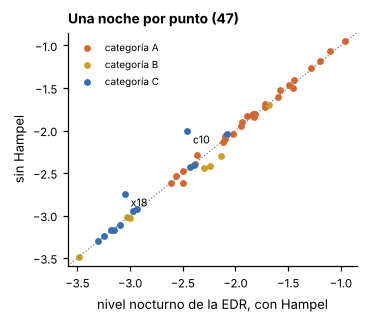

In [11]:
niv = pd.DataFrame({"actual": T_ACT.groupby("record").EDR_noche.first(),
                    "sin Hampel": TABLAS[frozenset({4})].groupby("record").EDR_noche.first()})
niv["categoría"] = niv.index.map(CATEGORIA)
niv["% de minutos con apnea"] = 100 * T_ACT[T_ACT.label >= 0].groupby("record").label.mean()
niv["cambio"] = niv["sin Hampel"] - niv["actual"]
fig, ax = plt.subplots(figsize=(3.4, 3.0))
for cat, g in niv.groupby("categoría"):
    ax.scatter(g["actual"], g["sin Hampel"], s=12, color=COLORES_CAT[cat], label=f"categoría {cat}")
lim = [niv[["actual", "sin Hampel"]].min().min() - 0.1, niv[["actual", "sin Hampel"]].max().max() + 0.1]
ax.plot(lim, lim, color=GRIS, ls=":", lw=0.8)
for rec in niv.cambio.abs().nlargest(2).index:
    ax.annotate(rec, (niv.loc[rec, "actual"], niv.loc[rec, "sin Hampel"]), fontsize=7, xytext=(4, -8), textcoords="offset points")
ax.set(xlabel="nivel nocturno de la EDR, con Hampel", ylabel="sin Hampel", title="Una noche por punto (47)", xlim=lim, ylim=lim)
ax.legend(fontsize=6.5)
fig.tight_layout()
save(fig, "07_hampel")
print("especificidad: actual", round(metricas(r_act.label, r_act.pred)["especificidad"], 3),
      "· sin Hampel", round(metricas(CVS[4].label, CVS[4].pred)["especificidad"], 3))
niv.reindex(niv.cambio.abs().sort_values(ascending=False).index).head(5).round(3)

## 5. El detector simplificado y el chequeo de la combinación

Las etapas que no cumplen ninguna condición se reemplazan **juntas** por su alternativa simple. Cada prueba anterior cambiaba una sola etapa; ahora hay que verificar que quitar varias a la vez no empeore. Es una comparación única: si el simplificado es peor de forma demostrable (p < 0,05), se restituye la etapa quitada con la mayor diferencia individual a su favor y se repite el chequeo.

In [12]:
def combinar(cumple, fam, personas, sorteos, r_a, mostrar=False):
    """Quita juntas las etapas que no cumplen y verifica que la combinación no sea peor."""
    dif = {k: fam[NOMBRES[k]][0] for k in OPCION}
    dif[7] = np.nanmax([fam[NOMBRES["7a"]][0], fam[NOMBRES["7b"]][0]])
    quitar = sorted(k for k, v in cumple.items() if not any(v.values()))
    while True:
        r_s = cv_c(con_ev(de(tabla_comb(quitar), personas), None if 7 in quitar else MINUTE_MAX_CORRECTED))
        d, boot, n = comparar(r_a, r_s, sorteos)
        p = p_bootstrap(boot)
        peor = bool(d > 0 and p < 0.05)
        if mostrar:
            print(f"etapas quitadas {quitar}: actual − simplificado = {d:+.4f} "
                  f"(IC 95 % {np.nanpercentile(boot, 2.5):+.4f} a {np.nanpercentile(boot, 97.5):+.4f}), p = {p:.3f}, "
                  f"{n} minutos comunes → {'peor: se restituye una etapa' if peor else 'no es peor'}")
        candidatas = [k for k in quitar if k in dif]
        if not peor or not candidatas:
            return quitar, r_s
        quitar.remove(max(candidatas, key=dif.get))


QUITADAS, r_sim = combinar(CUMPLE, FAM, PERSONAS, SORTEOS, r_act, mostrar=True)
T_SIM = tabla_comb(QUITADAS)

etapas quitadas [2, 3, 5, 6, 7, 8]: actual − simplificado = -0.0122 (IC 95 % -0.0363 a +0.0148), p = 0.334, 22772 minutos comunes → no es peor


**Los efectos no se suman.** Cada etapa por separado parecía aportar algo de exactitud (Wiener +0,006, cúbica +0,005, exclusión +0,013), pero con todas quitadas a la vez el detector no empeora. La razón es que cada versión elige su propio w y su propio umbral en cada grupo, y con cambios chicos en las señales esa elección salta de un valor de la grilla a otro. Diferencias de ~0,01 en la exactitud están en ese nivel de variación, y por eso ninguna resiste la corrección:

In [13]:
pd.DataFrame({"w actual": r_act.groupby("grupo").w.first(), "w simplificado": r_sim.groupby("grupo").w.first(),
              "umbral actual": r_act.groupby("grupo").umbral.first(), "umbral simplificado": r_sim.groupby("grupo").umbral.first()},
             ).rename_axis("grupo de la validación cruzada").round(3)

,w actual,w simplificado,umbral actual,umbral simplificado
grupo de la validación cruzada,,,,
0,1.50,1.25,0.240,0.430
1,0.75,0.75,0.473,0.604
2,1.00,1.00,0.353,0.474
3,1.25,1.00,0.460,0.641
4,1.00,1.00,0.536,0.564


## 6. El detector actual y el simplificado, lado a lado

Todas las medidas salen de la validación cruzada en desarrollo y son **descriptivas**. P1, P2 y P3 se calculan igual que en `04` §14, pero no son una prueba de la hipótesis: la hipótesis se armó con estos datos.

In [14]:
def resumen(t, r, nombre):
    e = r
    den = [auc(g.P_RR, g.label) for _, g in e.groupby("record")
           if min((g.label == 1).sum(), (g.label == 0).sum()) >= MIN_MINUTES_PER_CLASS]
    nn = e.groupby("record").agg(real=("label", "mean"), est=("pred", "mean"), EDR_noche=("EDR_noche", "first"))
    nn["categoria"] = nn.index.map(CATEGORIA)
    con_etiqueta = (t.label >= 0) & np.isfinite(t.P_RR)
    return {"detector": nombre, **metricas(e.label, e.pred),
            "AUC con personas no vistas": float(np.nanmean([auc(g.margen, g.label) for _, g in e.groupby("grupo")])),
            "P1 · AUC dentro de la noche del RR": float(np.mean(den)),
            "P2 · ρ nivel EDR vs % de apnea": spearmanr(nn.EDR_noche, nn.real)[0],
            "P3 · AUC de C (márgenes de la validación cruzada)": auc(e.margen, e.label),
            "ρ por noche": spearmanr(nn.real, nn.est)[0],
            "% marcado en controles": 100 * nn[nn.categoria == "C"].est.mean(),
            "% de minutos con etiqueta que clasifica": 100 * len(e) / int(con_etiqueta.sum())}


lado = pd.DataFrame([resumen(T_ACT, r_act, "actual (evaluada en test)"),
                     resumen(T_SIM, r_sim, "simplificado")]).set_index("detector").T
lado.round(3)

detector,actual (evaluada en test),simplificado
sensibilidad,0.814,0.801
especificidad,0.851,0.879
exactitud,0.836,0.848
AUC con personas no vistas,0.907,0.911
P1 · AUC dentro de la noche del RR,0.908,0.906
P2 · ρ nivel EDR vs % de apnea,0.825,0.781
P3 · AUC de C (márgenes de la validación cruzada),0.920,0.912
ρ por noche,0.795,0.803
% marcado en controles,7.376,4.804
% de minutos con etiqueta que clasifica,99.411,100.000


PosixPath('/home/user/TP-PSB-G8/informe/figuras/07_actual_vs_simplificado.png')

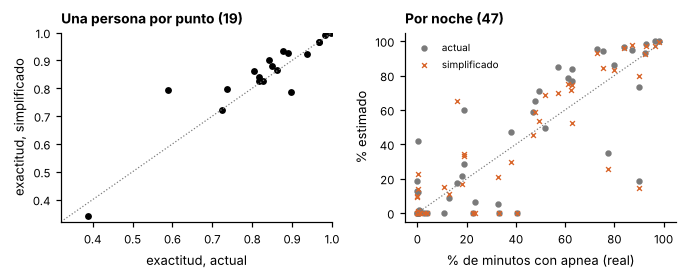

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(ANCHO, 2.6))
pa = r_act.assign(ok=r_act.pred == r_act.label).groupby("subject").ok.mean()
ps = r_sim.assign(ok=r_sim.pred == r_sim.label).groupby("subject").ok.mean()
axs[0].scatter(pa, ps.reindex(pa.index), s=12, color="black")
lim = [min(pa.min(), ps.min()) - 0.02, 1]
axs[0].plot(lim, lim, color=GRIS, ls=":", lw=0.8)
axs[0].set(xlabel="exactitud, actual", ylabel="exactitud, simplificado", title="Una persona por punto (19)", xlim=lim, ylim=lim)
na = r_act.groupby("record").agg(real=("label", "mean"), est=("pred", "mean"))
ns = r_sim.groupby("record").agg(real=("label", "mean"), est=("pred", "mean"))
axs[1].scatter(100 * na.real, 100 * na.est, s=10, color=GRIS, label="actual")
axs[1].scatter(100 * ns.real, 100 * ns.est, s=10, color=APNEA, marker="x", label="simplificado")
axs[1].plot([0, 100], [0, 100], color=GRIS, ls=":", lw=0.8)
axs[1].set(xlabel="% de minutos con apnea (real)", ylabel="% estimado", title="Por noche (47)")
axs[1].legend(fontsize=6.5)
fig.tight_layout()
save(fig, "07_actual_vs_simplificado")

## 7. Los parámetros del detector simplificado

Se ajustan con todos los minutos de desarrollo, igual que en `04` §7 y §14: w es el que maximiza el AUC (de 0 a 3, cada 0,25), y el umbral es el de Youden. Se guardan en `docs/parametros_simplificado.json` junto con la configuración de las etapas. Este archivo **no** se evaluó en test.

In [16]:
e_sim = con_ev(T_SIM, None if 7 in QUITADAS else MINUTE_MAX_CORRECTED)
mc = None if 7 in QUITADAS else MINUTE_MAX_CORRECTED
w_sim = float(GRILLA_W[int(np.argmax([auc(c_score(e_sim, fit_c(e_sim, w, max_corrected=mc)), e_sim.label) for w in GRILLA_W]))])
p_sim = fit_c(e_sim, w_sim, max_corrected=mc)
u_sim = youden_threshold(c_score(e_sim, p_sim).to_numpy(), e_sim.label.to_numpy())
etapas_cfg = {"refinamiento_pico_r": 1 not in QUITADAS, "wiener_edr": 2 not in QUITADAS,
              "excluir_ectopicos_edr": 3 not in QUITADAS, "hampel_edr": 4 not in QUITADAS,
              "interpolacion": "cubic" if 5 not in QUITADAS else "linear",
              "tendencia_welch": "linear" if 6 not in QUITADAS else "constant",
              "max_rr_corregidos_por_minuto": MINUTE_MAX_CORRECTED if 7 not in QUITADAS else None,
              "confianza": 8 not in QUITADAS}
if 8 not in QUITADAS:
    etapas_cfg["cortes_confianza_mov_rel"] = [float(c) for c in np.quantile(e_sim.mov_rel, (0.5, 0.9))]
PARAMS_SIM = {"feature": "C(m) = (P_RR(m) - mu1)/s1 + w * (mediana_noche(P_EDR) - mu2)/s2",
              **{k: p_sim[k] for k in ("mu1", "s1", "mu2", "s2", "w")}, "umbral": u_sim,
              "banda_hz": list(BAND), "ventana_s": WINDOW_S, "etapas": etapas_cfg,
              "fijado_con": "47 registros de desarrollo (notebooks/07_simplificacion.ipynb)",
              "evaluacion": "solo validación cruzada por personas en desarrollo; sin evaluación independiente"}
save_params(ROOT / "docs" / "parametros_simplificado.json", PARAMS_SIM)
print(json.dumps(PARAMS_SIM, indent=2, ensure_ascii=False))

{
  "feature": "C(m) = (P_RR(m) - mu1)/s1 + w * (mediana_noche(P_EDR) - mu2)/s2",
  "mu1": -1.4934964914174096,
  "s1": 0.5952056650946452,
  "mu2": -2.02197242676589,
  "s2": 0.6111909816094626,
  "w": 1.0,
  "umbral": 0.6045171197172678,
  "banda_hz": [
    0.01,
    0.05
  ],
  "ventana_s": 240,
  "etapas": {
    "refinamiento_pico_r": true,
    "wiener_edr": false,
    "excluir_ectopicos_edr": false,
    "hampel_edr": true,
    "interpolacion": "linear",
    "tendencia_welch": "constant",
    "max_rr_corregidos_por_minuto": null,
    "confianza": false
  },
  "fijado_con": "47 registros de desarrollo (notebooks/07_simplificacion.ipynb)",
  "evaluacion": "solo validación cruzada por personas en desarrollo; sin evaluación independiente"
}


## 8. ¿Cuánto optimismo agrega elegir las etapas con los mismos datos?

Las etapas se eligieron con la misma validación cruzada que después mide al detector simplificado. Esa medida puede ser optimista, porque el procedimiento ya vio a todas las personas cuando decidió qué quitar (Varma y Simon, 2006). Para estimar el resultado sin ese sesgo se usa una **validación cruzada anidada**:

1. Se deja afuera un grupo de personas (los mismos 5 grupos de antes).
2. Con las otras personas se repite todo el procedimiento de las secciones 2 a 5: las pruebas, la corrección de Holm, la decisión y el chequeo de la combinación.
3. Con esas mismas personas se ajustan los parámetros del detector elegido.
4. Se clasifican las personas que quedaron afuera, que no intervinieron en nada.

Este control no estaba en el criterio registrado. Se agregó después de correr las secciones anteriores (queda anotado al final de `docs/criterio_parsimonia.md`) y no cambia ninguna decisión: solo mide cuánto vale el procedimiento con personas nuevas.

In [17]:
filas_n, preds_n = [], []
for k_out, gpo in enumerate(grupos_personas(PERSONAS)):
    afuera = set(gpo)
    tr = [p for p in PERSONAS if p not in afuera]
    so = sorteos_personas(tr, n=len(SORTEOS), semilla=2026)
    fam_i, r_a_i, _, _ = pruebas_etapas(tr, so)
    cumple_i, _ = decidir(fam_i, tr, so)
    quitar_i, _ = combinar(cumple_i, fam_i, tr, so, r_a_i)
    mc = None if 7 in quitar_i else MINUTE_MAX_CORRECTED
    t_i = tabla_comb(quitar_i)
    e_tr, e_te = con_ev(de(t_i, tr), mc), con_ev(de(t_i, afuera), mc)
    w_i = float(GRILLA_W[int(np.argmax([auc(c_score(e_tr, fit_c(e_tr, w, max_corrected=mc)), e_tr.label) for w in GRILLA_W]))])
    p_i = fit_c(e_tr, w_i, max_corrected=mc)
    u_i = youden_threshold(c_score(e_tr, p_i).to_numpy(), e_tr.label.to_numpy())
    preds_n.append(e_te.assign(pred=(c_score(e_te, p_i) > u_i).astype(int).to_numpy(), grupo=k_out))
    filas_n.append({"grupo afuera": k_out + 1, "personas afuera": len(afuera),
                    "etapas que se mantienen": ", ".join(str(k) for k in ETAPAS if k not in quitar_i),
                    "etapas que se quitan": ", ".join(map(str, quitar_i)), "w": w_i})
r_anid = pd.concat(preds_n, ignore_index=True)
pd.DataFrame(filas_n).set_index("grupo afuera")

,personas afuera,etapas que se mantienen,etapas que se quitan,w
grupo afuera,,,,
1,4,1,"2, 3, 4, 5, 6, 7, 8",1.50
2,4,"1, 8","2, 3, 4, 5, 6, 7",0.50
3,4,1,"2, 3, 4, 5, 6, 7, 8",1.00
4,4,1,"2, 3, 4, 5, 6, 7, 8",1.25
5,3,1,"2, 3, 4, 5, 6, 7, 8",1.00


In [18]:
d_n, boot_n, n_n = comparar(r_act, r_anid, SORTEOS)
anid = pd.DataFrame([{"detector": "actual (validación cruzada)", **metricas(r_act.label, r_act.pred), "minutos": len(r_act)},
                     {"detector": "simplificado (validación cruzada simple)", **metricas(r_sim.label, r_sim.pred), "minutos": len(r_sim)},
                     {"detector": "procedimiento completo (validación cruzada anidada)", **metricas(r_anid.label, r_anid.pred), "minutos": len(r_anid)}]
                    ).set_index("detector")
print(f"actual − procedimiento anidado, sobre {n_n} minutos comunes: {d_n:+.4f} "
      f"(IC 95 % {np.nanpercentile(boot_n, 2.5):+.4f} a {np.nanpercentile(boot_n, 97.5):+.4f}), p = {p_bootstrap(boot_n):.3f}")
anid.round(3)

actual − procedimiento anidado, sobre 22772 minutos comunes: +0.0134 (IC 95 % -0.0105 a +0.0405), p = 0.302


,sensibilidad,especificidad,exactitud,minutos
detector,,,,
actual (validación cruzada),0.814,0.851,0.836,22772
simplificado (validación cruzada simple),0.801,0.879,0.848,22907
procedimiento completo (validación cruzada anidada),0.802,0.834,0.821,22907
